# 06 — ResearchMate: Combined-text vs Keyword-only Retrieval

**Goal:** Preserve the original TF-IDF/BM25 baselines on **title + abstract + keywords**, and evaluate additional **keyword-only** TF-IDF/BM25 rankings for the *same query*. Keep the existing MiniLM semantic comparisons as a separate benchmark.

| Method | Input | Score column |
|---|---|---|
| TF-IDF (original) | Title + abstract + keywords | `tfidf_score` |
| BM25 (original) | Title + abstract + keywords | `bm25_score` |
| TF-IDF (new) | Keywords only | `tfidf_keywords_score` |
| BM25 (new) | Keywords only | `bm25_keywords_score` |
| MiniLM | Keywords; title + abstract | `query_keywords_similarity`; `query_title_abstract_similarity` |
| Weighted MiniLM (existing) | 75% title + abstract, 25% keywords | `weighted_similarity_75_25` |

**Important:** Missing keywords are treated as unavailable (`NaN`), not as zero relevance. Original baselines are retained rather than overwritten. The ranking comparison is descriptive, not a relevance evaluation without labelled ground truth.

**Input:** `papers_final_verified.csv` in the current working directory. Run cells top to bottom. Install dependencies once if needed: `pip install pandas numpy scipy scikit-learn rank-bm25 sentence-transformers matplotlib`.

## 1. Imports, settings and load data

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

DATA_FILE = Path("papers_final_verified.csv")
QUERY = "evolution of gene expression plasticity under fluctuating temperature"
TOP_K = 10

if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE.resolve()}")
df = pd.read_csv(DATA_FILE)
required = ["doi", "title", "abstract", "keywords", "author", "year"]
missing = [name for name in required if name not in df.columns]
if missing:
    raise ValueError(f"Required dataset columns missing: {missing}")
if df.empty:
    raise ValueError("The dataset contains no papers")
df = df.reset_index(drop=True).copy()
print(f"Loaded {len(df)} papers; query: {QUERY}")

Loaded 17 papers; query: evolution of gene expression plasticity under fluctuating temperature


## 2. Text representations and metadata coverage
Use the same light cleaning strategy as notebook 05. `retrieval_text` includes title, abstract and keywords; `keywords_text` contains only supplied keyword metadata. We do **not** infer keywords from the abstract.

In [2]:
def clean_text(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value).replace("\n", " ").replace("\r", " ")).strip()

def clean_keywords(value):
    text = clean_text(value)
    return re.sub(r"\s+", " ", re.sub(r"[;|,]+", " ", text)).strip()

for col in ("doi", "title", "abstract", "keywords", "author"):
    df[col] = df[col].fillna("").astype(str)
df["title_clean"] = df["title"].map(clean_text)
df["abstract_clean"] = df["abstract"].map(clean_text)
df["keywords_clean"] = df["keywords"].map(clean_keywords)
df["keywords_text"] = df["keywords_clean"]
df["title_abstract_text"] = (df["title_clean"] + " " + df["abstract_clean"]).str.strip()
df["retrieval_text"] = (df["title_clean"] + " " + df["abstract_clean"] + " " + df["keywords_clean"]).str.strip()

has_keywords = df["keywords_text"].str.strip().ne("")
print(f"Keyword metadata: {has_keywords.sum()}/{len(df)} papers ({has_keywords.mean():.1%})")
print(f"Missing keywords: {(~has_keywords).sum()}")
print(f"Empty combined retrieval text: {df['retrieval_text'].eq('').sum()}")
display(df[["title_clean", "keywords_text", "retrieval_text"]].head(3))

Keyword metadata: 12/17 papers (70.6%)
Missing keywords: 5
Empty combined retrieval text: 0


,title_clean,keywords_text,retrieval_text
0,New Levels of Transcriptome Complexity at Uppe...,Drosophila heat stress splicing thermal extrem...,New Levels of Transcriptome Complexity at Uppe...
1,Cold acclimation wholly reorganizes the Drosop...,,Cold acclimation wholly reorganizes the Drosop...
2,Selection on adaptive and maladaptive gene exp...,,Selection on adaptive and maladaptive gene exp...


## 3. Original baselines — combined retrieval text
These reproduce the original scoring logic from notebook 05. Scores depend on the document collection and query; BM25 and TF-IDF scores are on different scales.

In [3]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

def tfidf_scores(texts, query):
    vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), lowercase=True)
    try:
        matrix = vectorizer.fit_transform(texts)
    except ValueError as exc:
        if "empty vocabulary" in str(exc).lower():
            return np.full(len(texts), np.nan)
        raise
    return cosine_similarity(vectorizer.transform([query]), matrix).ravel()

def bm25_scores(texts, query):
    tokens = [tokenize(t) for t in texts]
    if not any(tokens):
        return np.full(len(texts), np.nan)
    # Preserve the original default BM25Okapi settings.
    return BM25Okapi(tokens).get_scores(tokenize(query))

df["tfidf_score"] = tfidf_scores(df["retrieval_text"].tolist(), QUERY)
df["bm25_score"] = bm25_scores(df["retrieval_text"].tolist(), QUERY)
display(df.nlargest(min(TOP_K, len(df)), "tfidf_score")[["title_clean", "tfidf_score", "bm25_score"]])

,title_clean,tfidf_score,bm25_score
10,Evolution and Plasticity of the Transcriptome ...,0.327836,8.707753
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097,4.514744
2,Selection on adaptive and maladaptive gene exp...,0.143097,2.510066
3,Developmental plasticity evolved according to ...,0.136404,5.625873
6,Single-nucleus multiome sequencing reveals the...,0.099030,2.750376
9,Experimental evolution-induced transcriptome a...,0.096951,3.537311
5,Phenotypic Plasticity of the Drosophila Transc...,0.066580,3.658596
15,Regulation of gene expression and RNA editing ...,0.065796,2.910909
4,Phenotypic plasticity in response to temperatu...,0.063521,3.935826
0,New Levels of Transcriptome Complexity at Uppe...,0.060903,3.040358


## 4. New baselines — keywords only
Fit new lexical models **only on records with non-empty keyword metadata**. Every document is scored against the same full user query as in Section 3. Papers without keywords keep missing keyword-based scores.

In [4]:
df["tfidf_keywords_score"] = np.nan
df["bm25_keywords_score"] = np.nan

keyword_indices = df.index[has_keywords]
keyword_texts = df.loc[keyword_indices, "keywords_text"].tolist()
if keyword_texts:
    df.loc[keyword_indices, "tfidf_keywords_score"] = tfidf_scores(keyword_texts, QUERY)
    # BM25 tokenization may produce empty documents for punctuation-only values.
    valid_indices = [i for i in keyword_indices if tokenize(df.at[i, "keywords_text"])]
    if valid_indices:
        valid_texts = df.loc[valid_indices, "keywords_text"].tolist()
        df.loc[valid_indices, "bm25_keywords_score"] = bm25_scores(valid_texts, QUERY)
else:
    print("No non-empty keyword metadata: keyword-only scores cannot be estimated")

display(df.sort_values("tfidf_keywords_score", ascending=False, na_position="last")
        [["title_clean", "keywords_text", "tfidf_keywords_score", "bm25_keywords_score"]].head(TOP_K))

,title_clean,keywords_text,tfidf_keywords_score,bm25_keywords_score
13,The Evolution of Phenotypic Plasticity in Resp...,Drosophila experimental evolution gene express...,0.564427,4.190037
10,Evolution and Plasticity of the Transcriptome ...,RNA-seq adaptive evolution experimental evolut...,0.515957,4.099129
3,Developmental plasticity evolved according to ...,Drosophila experimental evolution performance ...,0.197408,2.241317
6,Single-nucleus multiome sequencing reveals the...,Embryogenesis Gene regulatory networks Plasticity,0.130307,1.217859
16,A simple genetic basis of adaptation to a nove...,Evolve and resequence Experimental evolution P...,0.054018,0.633593
11,Expression Profiling of the Wheat Pathogen Zym...,Mycosphaerella graminicola RNA-seq gene duplic...,0.043339,0.557926
4,Phenotypic plasticity in response to temperatu...,Adaptation climatic variability genotype heat ...,0.041445,0.308986
0,New Levels of Transcriptome Complexity at Uppe...,Drosophila heat stress splicing thermal extrem...,0.000000,0.000000
7,Comparative transcriptomic analyses of Zymosep...,RNA sequencing Septoria leaf blotch Zymoseptor...,0.000000,0.000000
8,Mapping genomic regions associated with temper...,Mycosphaerella graminicola QTL fungi heat stre...,0.000000,0.000000


## 5. Compare lexical rankings
Rank methods **within the same set of eligible papers** for a fair comparison. Top-k overlap and Spearman correlation measure changes in rankings, **not** retrieval accuracy. Ties (especially zero scores) can make ordering less informative.

In [5]:
method_pairs = [
    ("tfidf_score", "tfidf_keywords_score", "TF-IDF"),
    ("bm25_score", "bm25_keywords_score", "BM25"),
]
rows = []
for combined_col, keywords_col, label in method_pairs:
    eligible = df.dropna(subset=[combined_col, keywords_col]).copy()
    eligible["combined_rank"] = eligible[combined_col].rank(ascending=False, method="min")
    eligible["keyword_rank"] = eligible[keywords_col].rank(ascending=False, method="min")
    k = min(TOP_K, len(eligible))
    rho = eligible["combined_rank"].corr(eligible["keyword_rank"], method="spearman") if len(eligible) >= 2 else np.nan
    combined_top = set(eligible.nlargest(k, combined_col).index) if k else set()
    keywords_top = set(eligible.nlargest(k, keywords_col).index) if k else set()
    rows.append({"method": label, "eligible_papers": len(eligible),
                 "spearman_rho": rho, "top_k": k, "top_k_overlap": len(combined_top & keywords_top)})
    print(f"\n{label}: combined vs keyword-only (same {len(eligible)} eligible papers)")
    display(eligible.nlargest(k, keywords_col)
            [["title_clean", combined_col, keywords_col, "combined_rank", "keyword_rank"]])
comparison_summary = pd.DataFrame(rows)
display(comparison_summary)


TF-IDF: combined vs keyword-only (same 12 eligible papers)


,title_clean,tfidf_score,tfidf_keywords_score,combined_rank,keyword_rank
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097,0.564427,2.0,1.0
10,Evolution and Plasticity of the Transcriptome ...,0.327836,0.515957,1.0,2.0
3,Developmental plasticity evolved according to ...,0.136404,0.197408,3.0,3.0
6,Single-nucleus multiome sequencing reveals the...,0.099030,0.130307,4.0,4.0
16,A simple genetic basis of adaptation to a nove...,0.030829,0.054018,8.0,5.0
11,Expression Profiling of the Wheat Pathogen Zym...,0.028116,0.043339,10.0,6.0
4,Phenotypic plasticity in response to temperatu...,0.063521,0.041445,6.0,7.0
0,New Levels of Transcriptome Complexity at Uppe...,0.060903,0.000000,7.0,8.0
7,Comparative transcriptomic analyses of Zymosep...,0.000000,0.000000,12.0,8.0
8,Mapping genomic regions associated with temper...,0.030456,0.000000,9.0,8.0



BM25: combined vs keyword-only (same 12 eligible papers)


,title_clean,bm25_score,bm25_keywords_score,combined_rank,keyword_rank
13,The Evolution of Phenotypic Plasticity in Resp...,4.514744,4.190037,3.0,1.0
10,Evolution and Plasticity of the Transcriptome ...,8.707753,4.099129,1.0,2.0
3,Developmental plasticity evolved according to ...,5.625873,2.241317,2.0,3.0
6,Single-nucleus multiome sequencing reveals the...,2.750376,1.217859,7.0,4.0
16,A simple genetic basis of adaptation to a nove...,1.628860,0.633593,10.0,5.0
11,Expression Profiling of the Wheat Pathogen Zym...,1.801720,0.557926,9.0,6.0
4,Phenotypic plasticity in response to temperatu...,3.935826,0.308986,4.0,7.0
0,New Levels of Transcriptome Complexity at Uppe...,3.040358,0.000000,6.0,8.0
7,Comparative transcriptomic analyses of Zymosep...,0.763765,0.000000,12.0,8.0
8,Mapping genomic regions associated with temper...,1.426954,0.000000,11.0,8.0


,method,eligible_papers,spearman_rho,top_k,top_k_overlap
0,TF-IDF,12,0.754118,10,9
1,BM25,12,0.609096,10,8


## 6. Original MiniLM semantic comparison (preserved)
The semantic model remains independent of the TF-IDF/BM25 experiments. As in the original notebook, MiniLM uses lightly cleaned text and normalized embeddings. Empty keyword strings are not assigned meaningful semantic similarity.

In [6]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
query_embedding = model.encode([QUERY], normalize_embeddings=True)
title_abstract_embeddings = model.encode(
    df["title_abstract_text"].tolist(), normalize_embeddings=True, show_progress_bar=True
)
df["query_title_abstract_similarity"] = cosine_similarity(
    query_embedding, title_abstract_embeddings).ravel()

df["query_keywords_similarity"] = np.nan
keyword_embeddings = None
if has_keywords.any():
    keyword_embeddings = model.encode(
        df.loc[has_keywords, "keywords_text"].tolist(),
        normalize_embeddings=True, show_progress_bar=True
    )
    df.loc[has_keywords, "query_keywords_similarity"] = cosine_similarity(
        query_embedding, keyword_embeddings).ravel()

df["weighted_similarity_75_25"] = np.where(
    df["query_keywords_similarity"].notna(),
    0.75 * df["query_title_abstract_similarity"] + 0.25 * df["query_keywords_similarity"],
    df["query_title_abstract_similarity"]
)
display(df.nlargest(min(TOP_K, len(df)), "weighted_similarity_75_25")
        [["title_clean", "query_keywords_similarity", "query_title_abstract_similarity", "weighted_similarity_75_25"]])

/Users/ekta/Desktop/Sabudh Internship/ResearchMate/Code/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1119 19:36:36.138000 9977 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Batches: 100%|██████████| 1/1 [00:00<00:00, 37.11it/s]


,title_clean,query_keywords_similarity,query_title_abstract_similarity,weighted_similarity_75_25
13,The Evolution of Phenotypic Plasticity in Resp...,0.778096,0.777268,0.777475
10,Evolution and Plasticity of the Transcriptome ...,0.796122,0.623912,0.666964
3,Developmental plasticity evolved according to ...,0.647887,0.641563,0.643144
9,Experimental evolution-induced transcriptome a...,0.589518,0.636062,0.624426
4,Phenotypic plasticity in response to temperatu...,0.605338,0.614744,0.612393
0,New Levels of Transcriptome Complexity at Uppe...,0.581030,0.584999,0.584006
2,Selection on adaptive and maladaptive gene exp...,NaN,0.575526,0.575526
6,Single-nucleus multiome sequencing reveals the...,0.588197,0.556058,0.564093
16,A simple genetic basis of adaptation to a nove...,0.534144,0.522769,0.525613
5,Phenotypic Plasticity of the Drosophila Transc...,NaN,0.521722,0.521722


## 7. Compact comparison plot
Compare **rank positions**, not raw scores, because TF-IDF, BM25 and MiniLM have different score scales. This plot shows the four lexical rankings among papers with both keyword scores.

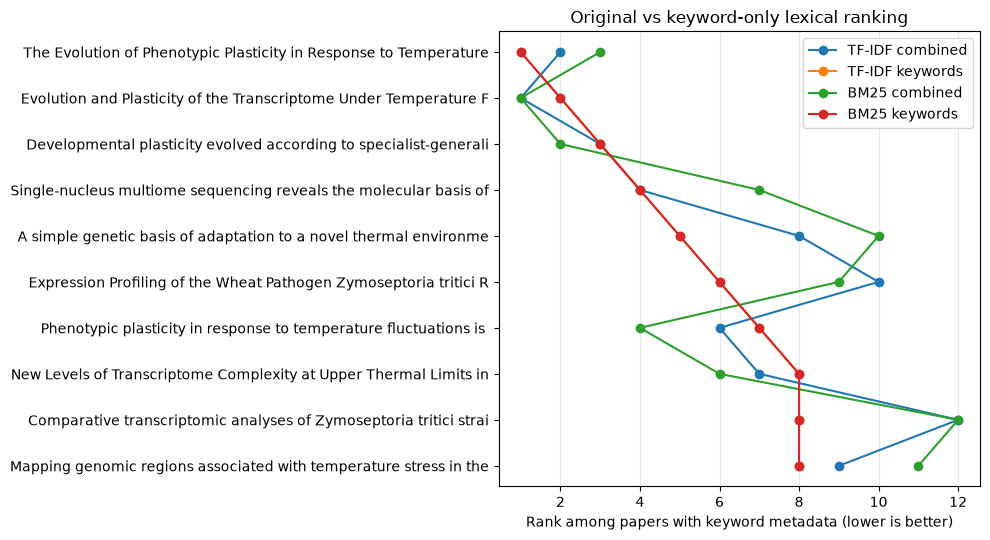

In [7]:
plot_df = df.dropna(subset=["tfidf_score", "bm25_score", "tfidf_keywords_score", "bm25_keywords_score"]).copy()
if len(plot_df):
    plot_df = plot_df.nlargest(min(TOP_K, len(plot_df)), "tfidf_keywords_score")
    rank_sources = df.loc[df.index.isin(df.dropna(subset=["tfidf_keywords_score", "bm25_keywords_score"]).index)]
    columns = ["tfidf_score", "tfidf_keywords_score", "bm25_score", "bm25_keywords_score"]
    ranks = rank_sources[columns].rank(ascending=False, method="min")
    names = ["TF-IDF combined", "TF-IDF keywords", "BM25 combined", "BM25 keywords"]
    fig, ax = plt.subplots(figsize=(10, max(4, len(plot_df)*0.55)))
    y = np.arange(len(plot_df))
    for column, name in zip(columns, names):
        ax.plot(ranks.loc[plot_df.index, column], y, marker="o", label=name)
    ax.set_yticks(y, [str(title)[:65] for title in plot_df["title_clean"]])
    ax.invert_yaxis()
    ax.set_xlabel("Rank among papers with keyword metadata (lower is better)")
    ax.set_title("Original vs keyword-only lexical ranking")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No keyword-scored papers available for ranking plot")

## 8. Export results
The CSV preserves the old score names for downstream compatibility and adds the two new keyword-only columns. Embeddings are saved for reuse; keyword embedding rows correspond to `keyword_embedding_indices.npy`.

In [8]:
result_columns = [
    "doi", "title", "author", "year", "keywords", "retrieval_text", "keywords_text",
    "tfidf_score", "bm25_score", "tfidf_keywords_score", "bm25_keywords_score",
    "query_keywords_similarity", "query_title_abstract_similarity", "weighted_similarity_75_25"
]
df[result_columns].to_csv("retrieval_embedding_results.csv", index=False)
comparison_summary.to_csv("06_lexical_ranking_summary.csv", index=False)
np.save("query_embedding.npy", query_embedding)
np.save("title_abstract_embeddings.npy", title_abstract_embeddings)
if keyword_embeddings is not None:
    np.save("keyword_embeddings.npy", keyword_embeddings)
    np.save("keyword_embedding_indices.npy", df.index[has_keywords].to_numpy())
print("Saved retrieval_embedding_results.csv and 06_lexical_ranking_summary.csv")
print("Saved MiniLM embeddings (with keyword row indices when applicable)")

Saved retrieval_embedding_results.csv and 06_lexical_ranking_summary.csv
Saved MiniLM embeddings (with keyword row indices when applicable)


## Interpretation and limitations

- **What changed:** the original TF-IDF and BM25 remain based on `retrieval_text` (title + abstract + keywords). New TF-IDF and BM25 scores use `keywords_text` exclusively.
- **Missing keywords:** keyword-only methods cannot evaluate those papers; coverage must be reported alongside overlap/correlation.
- **Important BM25 caveat:** BM25 on short keyword lists may give different score behaviour from full-text BM25 due to document length and term statistics; this does not automatically mean better relevance.
- **Evaluation next step:** compare ranking methods using manually judged relevant papers with Precision@k / Recall@k / nDCG, ideally across multiple representative queries. Rankings alone do not establish accuracy.
- **Scope:** no PDF extraction, BM25 parameter sensitivity, or redundant weighted-score experiments here; these are outside this notebook’s core comparison.